### Desafio 2 - Detección de cardiopatía

- Nombre: Jose Ignacio Kuoman Jimenez
- Generacion: G76

In [74]:
# Importamos las librerías para hacer la pregunta 1
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [76]:
# Importamos las librerias para hacer la pregunta 2
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

In [78]:
# Importamos las librerias para hacer la pregunta 3
from sklearn.model_selection import GridSearchCV

In [80]:
# Importamos las librerias para hacer la pregunta 4
# Importamos la libreria para poder realizar el ROC y AUC
from sklearn.metrics import roc_curve, roc_auc_score

#### Descripción

En este proyecto deberás construir tres modelos de Machine Learning de ensambles secuenciales para determinar si una persona padece o no una cardiopatía, a partir de los datos.

La base de datos se compone de tres archivos: processed_cleveland.csv, processed_hungarian.csv y processed_switzerland.csv, cada uno representa muestras adquiridas de diferentes clínicas. Los atributos de la base de datos son:

- **age**: Edad del sujeto en años
- **sex**: Sexo (1 = Hombre, 0 = Mujer)
- **cp**: Tipo de dolor torácico
  - Valor 1: angina típica
  - Valor 2: angina atípica
  - Valor 3: dolor no anginoso
  - Valor 4: asintomático
- **trestbps**: Presión arterial en reposo (en mm Hg al ingreso en el hospital)
- **chol**: Colesterol sérico en mg/dl
- **fbs**: Glucemia en ayunas > 120 mg/dl (1 = verdadero; 0 = falso)
- **restecg**: Medición electrocardiográfica en reposo
  - 0 = normal
  - 1 = presenta anomalía de la onda ST-T
  - 2 = muestra hipertrofia ventricular izquierda probable o definida según los criterios de Estes
- **thalach**: Frecuencia cardíaca máxima alcanzada
- **exang**: Angina inducida por ejercicio (1 = sí; 0 = no)
- **oldpeak**: Depresión del ST inducida por el ejercicio en relación con el reposo
- **slope**: La pendiente del segmento ST de ejercicio máximo
  - Valor 1: pendiente ascendente
  - Valor 2: plano
  - Valor 3: pendiente descendente
- **ca**: Número de vasos mayores (0-3) coloreados por la fluoroscopia
- **thal**:
  - 3 = normal
  - 6 = defecto fijo
  - 7 = defecto reversible
- **num**: Diagnóstico de cardiopatía (estado de la enfermedad angiográfica)
  - Valor 0: < 50% de estrechamiento del diámetro
  - Valor 1: > 50% de estrechamiento del diámetro


El atributo **num** será la variable objetivo (0 sin enfermedad, 1 con enfermedad).

Para construir los modelos y resolver el problema, deberás aplicar los siguientes pasos:

#### Pregunta 1

1. Carga los datos de los tres archivos unidos en un DataFrame, y prepáralos considerando las siguientes etapas:

In [82]:
# Lista con los nombres de las columnas de las bases de datos que vamos a usar:
column_names = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 
                'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']

In [84]:
# Importamos la base de datos de Cleveland
df_cleveland = pd.read_csv('processed.cleveland.data', header = None, names = column_names)

In [86]:
df_cleveland.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [88]:
df_cleveland.shape

(303, 14)

In [90]:
# Importamos la base de datos de Hungarian
df_hungarian = pd.read_csv('processed.hungarian.data', header = None, names = column_names)

In [92]:
df_hungarian.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,28,1,2,130,132,0,2,185,0,0.0,?,?,?,0
1,29,1,2,120,243,0,0,160,0,0.0,?,?,?,0
2,29,1,2,140,?,0,0,170,0,0.0,?,?,?,0
3,30,0,1,170,237,0,1,170,0,0.0,?,?,6,0
4,31,0,2,100,219,0,1,150,0,0.0,?,?,?,0


In [94]:
df_hungarian.shape

(294, 14)

In [96]:
# Importamos la base de datos de switzerland
df_switzerland = pd.read_csv('processed.switzerland.data', header = None, names = column_names)

In [98]:
df_switzerland.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,32,1,1,95,0,?,0,127,0,.7,1,?,?,1
1,34,1,4,115,0,?,?,154,0,.2,1,?,?,1
2,35,1,4,?,0,?,0,130,1,?,?,?,7,3
3,36,1,4,110,0,?,0,125,1,1,2,?,6,1
4,38,0,4,105,0,?,0,166,0,2.8,1,?,?,2


In [100]:
df_switzerland.shape

(123, 14)

##### Unimos los 3 dataframes en un solo dataframe.

- `ignore_index=True` -> ignoramos el indice original de los dataframes y generamos un nuevo indice secuencial en el DataFrame df, lo hacemos debido a que hemos unido 3 dataframes en uno solo y quiero tenerlo en un indice continuo.

In [102]:
df = pd.concat([df_cleveland, df_hungarian, df_switzerland], ignore_index=True)

In [104]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [106]:
df.shape

(720, 14)

##### Lo cual es correcto, debido a que si sumamos las filas de los 3 DataFrames salen 720 filas

- df_cleveland.shape -> (303, 14)
- df_hungarian.shape -> (294, 14)
- df_switzerland.shape -> (123, 14)

Resultado 303 + 294 + 123 = 720

In [108]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 720 entries, 0 to 719
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       720 non-null    float64
 1   sex       720 non-null    float64
 2   cp        720 non-null    float64
 3   trestbps  720 non-null    object 
 4   chol      720 non-null    object 
 5   fbs       720 non-null    object 
 6   restecg   720 non-null    object 
 7   thalach   720 non-null    object 
 8   exang     720 non-null    object 
 9   oldpeak   720 non-null    object 
 10  slope     720 non-null    object 
 11  ca        720 non-null    object 
 12  thal      720 non-null    object 
 13  num       720 non-null    int64  
dtypes: float64(3), int64(1), object(10)
memory usage: 78.9+ KB


##### A considerar
Las variables categoricas según la hoja del Desafío 2 - Detección de cardiopatía
- **sex**: Sexo (1 = Hombre, 0 = Mujer)
- **cp**: Tipo de dolor torácico
- **fbs**: Glucemia en ayunas > 120 mg/dl (1 = verdadero; 0 = falso)
- **restecg**: Medición electrocardiográfica en reposo
- **exang**: Angina inducida por ejercicio (1 = sí; 0 = no)
- **slope**: La pendiente del segmento ST de ejercicio máximo
- **ca**: Número de vasos mayores (0-3) coloreados por la fluoroscopia
- **thal**: 3 = normal; 6 = defecto fijo; 7 = defecto reversible
- **num**: Diagnóstico de cardiopatía (estado de la enfermedad angiográfica)

#### Pregunta 1

1. Desarrollo de la pregunta **a**

   **a**. Asigna a la variable objetivo **num** un cero cuando su valor es cero, y un 1 en otro caso. Muestra la cantidad de valores ausente por atributo. Procésalos considerando los siguientes criterios:
   - **i.** Si el atributo presenta un porcentaje de valores ausentes mayor a 25%, entonces descartamos ese atributo.
   - **ii.** Para los atributos con valores ausentes menores al 25% se deben rellenar con el valor promedio del atributo de acuerdo a la clase, es decir, los valores ausentes para los cuales **num=0** se deben rellenar con el promedio de los valores presentes para los cuales **num=0**.
   - **iii.** Para las variables categóricas, los valores a asignar (promedio) deben ser aproximados al valor entero más cercano.

Asigna a la variable objetivo **num** un cero cuando su valor es cero, y un 1 en otro caso

In [110]:
# Asigna a la variable objetivo num un cero cuando su valor es cero, y un 1 en otro caso
df['num'] = np.where(df['num'] == 0, 0, 1)

In [112]:
df['num'].value_counts(dropna = False)

num
0    360
1    360
Name: count, dtype: int64

#### Reemplazo de valores '?' por valores nulos

Debido a que los valores ausentes en df se encuentran representados por '?', procedemos estos a cambiarlos por valores nulos para representar mejor los datos.

In [114]:
# cambiamos los datos con '?' por np.nan
df.replace('?', np.nan, inplace=True)

##### Mostramos la cantidad de valores ausente por atributo

In [116]:
# Muestra la cantidad de valores ausente por atributo
df.isna().sum()

age           0
sex           0
cp            0
trestbps      3
chol         23
fbs          83
restecg       2
thalach       2
exang         2
oldpeak       6
slope       207
ca          413
thal        320
num           0
dtype: int64

##### Mostramos el porcentaje de valores ausente por atributo

In [118]:
# Muestra el porcentaje de valores ausente por atributo
df.isnull().mean() * 100

age          0.000000
sex          0.000000
cp           0.000000
trestbps     0.416667
chol         3.194444
fbs         11.527778
restecg      0.277778
thalach      0.277778
exang        0.277778
oldpeak      0.833333
slope       28.750000
ca          57.361111
thal        44.444444
num          0.000000
dtype: float64

##### Sacamos una copia de df con el nombre de df2 para no cambiar el dataframe original

In [120]:
df2 = df.copy()

In [122]:
df2.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [124]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 720 entries, 0 to 719
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       720 non-null    float64
 1   sex       720 non-null    float64
 2   cp        720 non-null    float64
 3   trestbps  717 non-null    object 
 4   chol      697 non-null    object 
 5   fbs       637 non-null    object 
 6   restecg   718 non-null    object 
 7   thalach   718 non-null    object 
 8   exang     718 non-null    object 
 9   oldpeak   714 non-null    object 
 10  slope     513 non-null    object 
 11  ca        307 non-null    object 
 12  thal      400 non-null    object 
 13  num       720 non-null    int32  
dtypes: float64(3), int32(1), object(10)
memory usage: 76.1+ KB


##### Procedemos a procesar los datos del dataframe df2 considerando los siguiente criterios que nos brinda el desafío:

- **i.** Si el atributo presenta un porcentaje de valores ausentes mayor a 25%, entonces descartamos ese atributo.

In [126]:
df2.isnull().mean() * 100

age          0.000000
sex          0.000000
cp           0.000000
trestbps     0.416667
chol         3.194444
fbs         11.527778
restecg      0.277778
thalach      0.277778
exang        0.277778
oldpeak      0.833333
slope       28.750000
ca          57.361111
thal        44.444444
num          0.000000
dtype: float64

Vamos a descartar las siguiente variables debido a que presentan un porcentaje de valores ausentes mayores a 25%:
- slope
- ca
- thal

In [128]:
# Eliminamos las columnas con más del 25% de valores ausentes
# Solamente incluimos a las columnas que poseen un 25% de datos o menos ausentes.
df2 = df2.loc[:, df2.isnull().mean() <= 0.25]

In [130]:
df2.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,0


Procedemos a validar que las columnas con más de 25% de datos ausentes se han eliminado correctamente

In [132]:
df2.isnull().mean() * 100

age          0.000000
sex          0.000000
cp           0.000000
trestbps     0.416667
chol         3.194444
fbs         11.527778
restecg      0.277778
thalach      0.277778
exang        0.277778
oldpeak      0.833333
num          0.000000
dtype: float64

Después de haber elimado las columnas con un porcentaje de valores ausentes mayores a 25%, pasamos a **identificar cuáles son las variables continuas y categoricas del df2**.

##### Recordamos lo siguiente
Las variables categoricas según la hoja del Desafío 2 - Detección de cardiopatía son la siguientes

- **sex**: Sexo (1 = Hombre, 0 = Mujer)
- **cp**: Tipo de dolor torácico
- **fbs**: Glucemia en ayunas > 120 mg/dl (1 = verdadero; 0 = falso)
- **restecg**: Medición electrocardiográfica en reposo
- **exang**: Angina inducida por ejercicio (1 = sí; 0 = no)
- **slope**: La pendiente del segmento ST de ejercicio máximo
- **ca**: Número de vasos mayores (0-3) coloreados por la fluoroscopia
- **thal**: 3 = normal; 6 = defecto fijo; 7 = defecto reversible
- **num**: Diagnóstico de cardiopatía (estado de la enfermedad angiográfica)

Pero recordemos que habíamos eliminado las siguientes variables por tener un porcentaje de valores ausentes mayores a 25%:

- **slope**: La pendiente del segmento ST de ejercicio máximo
- **ca**: Número de vasos mayores (0-3) coloreados por la fluoroscopia
- **thal**: 3 = normal; 6 = defecto fijo; 7 = defecto reversible

Por lo tanto, **las variables categoricas son las siguientes:**

- **sex**: Sexo (1 = Hombre, 0 = Mujer)
- **cp**: Tipo de dolor torácico
- **fbs**: Glucemia en ayunas > 120 mg/dl (1 = verdadero; 0 = falso)
- **restecg**: Medición electrocardiográfica en reposo
- **exang**: Angina inducida por ejercicio (1 = sí; 0 = no)
- **num**: Diagnóstico de cardiopatía (estado de la enfermedad angiográfica)

Y, por lo tanto, **las variables restantes vendrán a ser las variables continuas**, las cuales son las siguientes:

- **age**: Edad del sujeto en años
- **trestbps**: Presión arterial en reposo (en mm Hg al ingreso en el hospital)
- **chol**: Colesterol sérico en mg/dl
- **thalach**: Frecuencia cardíaca máxima alcanzada
- **oldpeak**: Depresión del ST inducida por el ejercicio en relación con el reposo


##### Las variables continuas y categoricas del dataframe df2 son las siguientes:

##### Variables continuas:
- age
- trestbps
- chol
- thalach
- oldpeak

##### Variables categoricas:
- sex
- cp
- fbs
- restecg
- exang
- num

In [134]:
df2.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,0


In [136]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 720 entries, 0 to 719
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       720 non-null    float64
 1   sex       720 non-null    float64
 2   cp        720 non-null    float64
 3   trestbps  717 non-null    object 
 4   chol      697 non-null    object 
 5   fbs       637 non-null    object 
 6   restecg   718 non-null    object 
 7   thalach   718 non-null    object 
 8   exang     718 non-null    object 
 9   oldpeak   714 non-null    object 
 10  num       720 non-null    int32  
dtypes: float64(3), int32(1), object(7)
memory usage: 59.2+ KB


Vemos que las variables continuas a excepción de 'age' se encuentran como tipo objeto.

##### Por lo cual, procedemos a convertir las variables continuas que se encuentran como object a float:
- trestbps
- chol
- thalach
- oldpeak

Recordar que no consideramos 'age' porque ya es dato float.

Explicación del código:

- pd.to_numeric(df['nombre_de_la_columna'], errors='coerce') me va convertir los valores de la columna 'nombre_de_la_columna' a float.
- Le agregamos errors='coerce' debido a que convierte cualquier valor no numerico en NaN, lo cual es muy útil debido a que si hay valores en la columna que se no puedan convertir directamente a float estos pasaran a ser NaN. Lo cual resulta muy beneficioso, debido a que cualquier dato no númerico mal ingresado lo convertiría en NaN.

In [138]:
df2['trestbps'] = pd.to_numeric(df2['trestbps'], errors='coerce')
df2['chol'] = pd.to_numeric(df2['chol'], errors='coerce')
df2['thalach'] = pd.to_numeric(df2['thalach'], errors='coerce')
df2['oldpeak'] = pd.to_numeric(df2['oldpeak'], errors='coerce')

Procedemos a visualizar los datos de cada una de las variables continuas:

In [140]:
df2['chol'].value_counts(dropna = False)

chol
0.0      123
NaN       23
230.0      8
246.0      8
211.0      8
        ... 
252.0      1
141.0      1
313.0      1
126.0      1
409.0      1
Name: count, Length: 203, dtype: int64

In [142]:
df2['thalach'].value_counts(dropna = False)

thalach
150.0    39
140.0    29
130.0    24
120.0    23
160.0    22
         ..
88.0      1
71.0      1
194.0     1
192.0     1
67.0      1
Name: count, Length: 115, dtype: int64

In [144]:
# Procedemos a revisar los tipos de datos del dataframe df2
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 720 entries, 0 to 719
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       720 non-null    float64
 1   sex       720 non-null    float64
 2   cp        720 non-null    float64
 3   trestbps  717 non-null    float64
 4   chol      697 non-null    float64
 5   fbs       637 non-null    object 
 6   restecg   718 non-null    object 
 7   thalach   718 non-null    float64
 8   exang     718 non-null    object 
 9   oldpeak   714 non-null    float64
 10  num       720 non-null    int32  
dtypes: float64(7), int32(1), object(3)
memory usage: 59.2+ KB


Procedemos ahora a pasar las variables categoricas a variables númericas con la finalidad de poder resolver más adelante el criterio iii.

##### convertimos las variables categoricas a float:
- sex
- cp
- fbs
- restecg
- exang
- num

##### Pero solamente vamos a convertir las siguientes variables a float debido a que las demás variables categóricas ya son númericas:
- fbs
- restecg
- exang


##### Volvemos a emplear el mismo método que utilizamos para pasar las variables continuas de object a númericas.

- pd.to_numeric(df['nombre_de_la_columna'], errors='coerce') me va convertir los valores de la columna 'nombre_de_la_columna' a float.
- Le agregamos errors='coerce' debido a que convierte cualquier valor no numerico en NaN, lo cual es muy útil debido a que si hay valores en la columna que se no puedan convertir directamente a float estos pasaran a ser NaN. Lo cual resulta muy beneficioso, debido a que cualquier dato no númerico mal ingresado lo convertiría en NaN.

In [146]:
df2.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,0


In [148]:
df2['fbs'] = pd.to_numeric(df2['fbs'], errors='coerce')
df2['restecg'] = pd.to_numeric(df2['restecg'], errors='coerce')
df2['exang'] = pd.to_numeric(df2['exang'], errors='coerce')

In [150]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 720 entries, 0 to 719
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       720 non-null    float64
 1   sex       720 non-null    float64
 2   cp        720 non-null    float64
 3   trestbps  717 non-null    float64
 4   chol      697 non-null    float64
 5   fbs       637 non-null    float64
 6   restecg   718 non-null    float64
 7   thalach   718 non-null    float64
 8   exang     718 non-null    float64
 9   oldpeak   714 non-null    float64
 10  num       720 non-null    int32  
dtypes: float64(10), int32(1)
memory usage: 59.2 KB


In [152]:
df2.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,0


In [154]:
df2['fbs'].value_counts(dropna = False)

fbs
0.0    567
NaN     83
1.0     70
Name: count, dtype: int64

##### Recordar lo siguiente:

Debido a que hemos agregado  errors='coerce' al momento de pasar los datos a números, los datos que no puedan ser pasados a números se harán NaN. Es decir, los datos que hayan sido mal registrados se haran NaN, lo cual indica que es probable que se haya aumentado la cantidad de valores nulos en las columnas que se han convertido a numericas.

##### Por lo cual, volvemos a calcular el porcentaje de valores nulos en las columnas en caso se haya aumentado considerablemente.

In [156]:
df2.isnull().mean() * 100

age          0.000000
sex          0.000000
cp           0.000000
trestbps     0.416667
chol         3.194444
fbs         11.527778
restecg      0.277778
thalach      0.277778
exang        0.277778
oldpeak      0.833333
num          0.000000
dtype: float64

Vemos que no es necesario eliminar otras columnas más debido a que no hay un porcentaje mayor al 25%.

##### Habiamos visto previamente que las variables continuas y categoricas del df2 son las siguientes:

##### Variables continuas:
- age
- trestbps
- chol
- thalach
- oldpeak

##### Variables categoricas:
- sex
- cp
- fbs
- restecg
- exang
- num

In [158]:
df2['chol'].value_counts(dropna = False)

chol
0.0      123
NaN       23
230.0      8
246.0      8
211.0      8
        ... 
252.0      1
141.0      1
313.0      1
126.0      1
409.0      1
Name: count, Length: 203, dtype: int64

##### Detección de datos mal ingresados (error humano)

Despues de haber revisado los datos de las variables del dataframe df2 para ver si todavía hay datos mal ingresados, nos pudimos fijar que en la variable 'chol' existen 123 datos con valor de 0.

Lo cual no es posible debido a que los niveles de colesterol varían dentro de un rango saludable entre 125 mg/dl y 200 mg/dl para adultos, aunque estos valores difieren un poco según la edad

##### Por lo cual, procedo a reemplazar los valores 0 por NaN en la columna 'chol' debido a que estos datos han sido mal ingresados.

In [160]:
df2['chol'] = df2['chol'].replace(0, np.nan)

In [162]:
# Validamos que se haya dado correctamente.
df2['chol'].value_counts(dropna = False)

chol
NaN      146
230.0      8
246.0      8
211.0      8
275.0      7
        ... 
409.0      1
141.0      1
358.0      1
412.0      1
393.0      1
Name: count, Length: 202, dtype: int64

Como realice el reemplazo de los valores 0 por NaN en la columna 'chol', procedo nuevamente calcular el porcentaje de valores ausentes por columna con la finalidad de ver principalmente si el reemplazo que hice en la columna 'chol' ha provocado que en la misma columna se tenga un porcentaje de valores ausentes mayores a 25%.

##### Nuevamente vemos el porcentaje de valores ausentes por atributo.

In [164]:
df2.isnull().mean() * 100

age          0.000000
sex          0.000000
cp           0.000000
trestbps     0.416667
chol        20.277778
fbs         11.527778
restecg      0.277778
thalach      0.277778
exang        0.277778
oldpeak      0.833333
num          0.000000
dtype: float64

Vemos que no es necesario eliminar la columna Chol, debido a que tienes menos del 25% de los datos ausentes.

##### Recordar que con los cambios realizados al dataframe df2, se nos hará ahora más sencillo aplicar los criterios ii y iii de la pregunta 1 a y poder, asimismo, acabar satisfactoriamente con las demás preguntas del desafío 2.

Los cambios principales que se dieron fueron los siguientes:

- Se eliminaron las columnas con valores ausentes mayores a 25%.
- Las variables continuas y categóricas no númericas se pasaron a númericas.
- Los datos con signos de interrogación y los datos no númericos se conviritieron en valores ausentes, NaN.

#### Pregunta 1 - a ii)

- **ii.** Para los atributos con valores ausentes menores al 25% se deben rellenar con el valor promedio del atributo de acuerdo a la clase, es decir, los valores ausentes para los cuales **num=0** se deben rellenar con el promedio de los valores presentes para los cuales **num=0**.

**Importante**

El punto **ii** solamente se va a aplicar a las variables continuas, debido a que las demás son variables categóricas y los valores ausentes de las variables categóricas se van a reemplazar en el punto **iii**.

##### Habíamos visto previamente que las variables continuas eran las siguientes:
- age
- trestbps
- chol
- thalach
- oldpeak

##### Y como el atributo 'age' no tiene valores ausentes y los demás atributos sí, procedemos a usar el criterio ii para los siguientes atributos:
- trestbps
- chol
- thalach
- oldpeak

In [166]:
# variables continuas que tienen un porcentaje de valores ausentes menores a 25%.
var_cont25 = ['trestbps', 'chol', 'thalach', 'oldpeak']

In [168]:
# (df2['num'] == 0) & (df2[col].isnull()) -> seleccioname las filas donde num = 0 y se tiene valor nulo en col.
# = df2[df2['num'] == 0][col].mean() -> El valor ausente se reemplaza con el promedio de los valores presentes en col donde num = 0.

# Rellenar los valores ausentes en cada variable continua según el promedio condicionado en 'num'
for col in var_cont25:
    df2.loc[(df2['num'] == 0) & (df2[col].isnull()), col] = df2[df2['num'] == 0][col].mean()
    df2.loc[(df2['num'] == 1) & (df2[col].isnull()), col] = df2[df2['num'] == 1][col].mean()

In [170]:
# validamos que se haya dado correctamente.
df2.isnull().mean() * 100

age          0.000000
sex          0.000000
cp           0.000000
trestbps     0.000000
chol         0.000000
fbs         11.527778
restecg      0.277778
thalach      0.000000
exang        0.277778
oldpeak      0.000000
num          0.000000
dtype: float64

#### Preguna 1 - a iii)

   - **iii.** Para las variables categóricas, los valores a asignar (promedio) deben ser aproximados al valor entero más cercano.

##### Habíamos visto previamente que las variables categóricas eran las siguientes:
- sex
- cp
- fbs
- restecg
- exang
- num

##### Y como los atributos 'sex', 'cp' y 'num' no tienen valores ausentes y los demás atributos sí, procedemos a usar el criterio iii para los siguientes atributos categóricos:

- fbs
- restecg
- exang

In [172]:
# variables categóricas que tienen un porcentaje de valores ausentes menores a 25%.

var_cat25 = ['fbs', 'restecg', 'exang']

In [174]:
# Rellenamos los valores ausentes en cada variable ordinal según el promedio redondeado a entero
for col in var_cat25:

    # redondeamos el promedio de los valores presentes y lo guardamos en la variable mean
    mean = round(df2[col].mean())

    # asignamos el promedio a los valores ausentes que se encuentren en la columna col
    df2.loc[df2[col].isnull(), col] = mean

In [176]:
# validamos que se haya dado correctamente.
df2.isnull().mean() * 100

age         0.0
sex         0.0
cp          0.0
trestbps    0.0
chol        0.0
fbs         0.0
restecg     0.0
thalach     0.0
exang       0.0
oldpeak     0.0
num         0.0
dtype: float64

##### Variables continuas:
- age
- trestbps
- chol
- thalach
- oldpeak

##### Variables categoricas:
- sex
- cp
- fbs
- restecg
- exang
- num

#### Pregunta 1 - b

1. Desarrollo de la b

      b. Construye variables **dummies** para las variables discretas con tres o más categorías.

In [178]:
# lista de variables categoricas
var_cat = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'num']

# hallando la lista de variables categoricas con 3 o mas categorias
var_cat3 = []
for col in var_cat:
    if len(df2[col].unique()) > 2:
        var_cat3.append(col)

In [180]:
# lista de variables categoricas con 3 o mas categorias
var_cat3

['cp', 'restecg']

In [182]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 720 entries, 0 to 719
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       720 non-null    float64
 1   sex       720 non-null    float64
 2   cp        720 non-null    float64
 3   trestbps  720 non-null    float64
 4   chol      720 non-null    float64
 5   fbs       720 non-null    float64
 6   restecg   720 non-null    float64
 7   thalach   720 non-null    float64
 8   exang     720 non-null    float64
 9   oldpeak   720 non-null    float64
 10  num       720 non-null    int32  
dtypes: float64(10), int32(1)
memory usage: 59.2 KB


In [184]:
df2[var_cat3]

,cp,restecg
0,1.0,2.0
1,4.0,2.0
2,4.0,2.0
3,3.0,0.0
4,2.0,2.0
...,...,...
715,4.0,1.0
716,4.0,0.0
717,3.0,2.0
718,3.0,1.0


##### sacamos una copia de df2 para conservarlo

In [186]:
df3 = df2.copy()

In [188]:
df3.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,0


##### Pasamos la variables categóricas con 3 o mas categorías a datos de tipo object con la finalidad de pasarlo a variables dummies.

In [190]:
for col in var_cat3:
    df3[col] =  df3[col].astype(object)

In [192]:
df3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 720 entries, 0 to 719
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       720 non-null    float64
 1   sex       720 non-null    float64
 2   cp        720 non-null    object 
 3   trestbps  720 non-null    float64
 4   chol      720 non-null    float64
 5   fbs       720 non-null    float64
 6   restecg   720 non-null    object 
 7   thalach   720 non-null    float64
 8   exang     720 non-null    float64
 9   oldpeak   720 non-null    float64
 10  num       720 non-null    int32  
dtypes: float64(8), int32(1), object(2)
memory usage: 59.2+ KB


In [194]:
# Conversión de las variables categoricas con 3 o mas categorias a variables dummies

df3_dummy = pd.get_dummies(df3[var_cat3], dtype=int, drop_first=True)

In [196]:
df3_dummy.head()

,cp_2.0,cp_3.0,cp_4.0,restecg_1.0,restecg_2.0
0,0,0,0,0,1
1,0,0,1,0,1
2,0,0,1,0,1
3,0,1,0,0,0
4,1,0,0,0,1


In [198]:
# procedemos a eliminar las variables categóricas de df3 para luego añadirlas como variables dummies
df3 = df3.drop(columns=['cp', 'restecg'])

In [200]:
df3.head()

,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,num
0,63.0,1.0,145.0,233.0,1.0,150.0,0.0,2.3,0
1,67.0,1.0,160.0,286.0,0.0,108.0,1.0,1.5,1
2,67.0,1.0,120.0,229.0,0.0,129.0,1.0,2.6,1
3,37.0,1.0,130.0,250.0,0.0,187.0,0.0,3.5,0
4,41.0,0.0,130.0,204.0,0.0,172.0,0.0,1.4,0


In [202]:
# procedemos a unir los dataframes
df3_concat = pd.concat([df3, df3_dummy], axis = 1)
df3_concat.head(5)

,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,num,cp_2.0,cp_3.0,cp_4.0,restecg_1.0,restecg_2.0
0,63.0,1.0,145.0,233.0,1.0,150.0,0.0,2.3,0,0,0,0,0,1
1,67.0,1.0,160.0,286.0,0.0,108.0,1.0,1.5,1,0,0,1,0,1
2,67.0,1.0,120.0,229.0,0.0,129.0,1.0,2.6,1,0,0,1,0,1
3,37.0,1.0,130.0,250.0,0.0,187.0,0.0,3.5,0,0,1,0,0,0
4,41.0,0.0,130.0,204.0,0.0,172.0,0.0,1.4,0,1,0,0,0,1


#### Preguna 1 - c

1. Desarrollo de la c

      c. Realiza un análisis descriptivo por variable visualizando histogramas y gráficos de barra según corresponda. Construye una matriz de correlaciones con un **heatmap**, para las variables continuas. Plantea tus observaciones y conclusiones.

Recordar que las variables continuas y categóricas son las siguientes:

##### Variables continuas:
- age
- trestbps
- chol
- thalach
- oldpeak

##### Variables categoricas:
- sex
- cp
- fbs
- restecg
- exang
- num

##### Vamos a utilizar el dataframe df2 para facilitar el desarrollo

In [205]:
df2.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,0


In [208]:
# lista con las variables categóricas
var_cat = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'num']

In [210]:
max = 0
for col in var_cat:
    if len(df2[col].unique()) > max:
        max = len(df2[col].unique())

In [212]:
# máximo número de categorías en una sola columna de df2.
max

4

In [214]:
# numero de variables en el dataframe df2
len(df2.columns)

11

In [224]:
def representacion_de_las_variables(df):
    plt.figure(figsize = (13, 9))

    for idx, col in enumerate(df.columns):
        
        # La numeracion de los subplot comienza 1, por lo que se usa idx+1.
        # idx+1 ademas te va indicar en que columna estas
        plt.subplot(4, 3, idx+1)
        plt.title(col)
        plt.xlabel('')

        if len(df[col].unique()) > 4:
            sns.histplot(x=col, kde = True, data=df)

        else:
            sns.countplot(y=df[col], hue=df[col], palette='viridis', dodge=False)

        plt.tight_layout()

##### Realizamos un análisis descriptivo por variable visualizando histogramas y gráficos de barra según corresponda

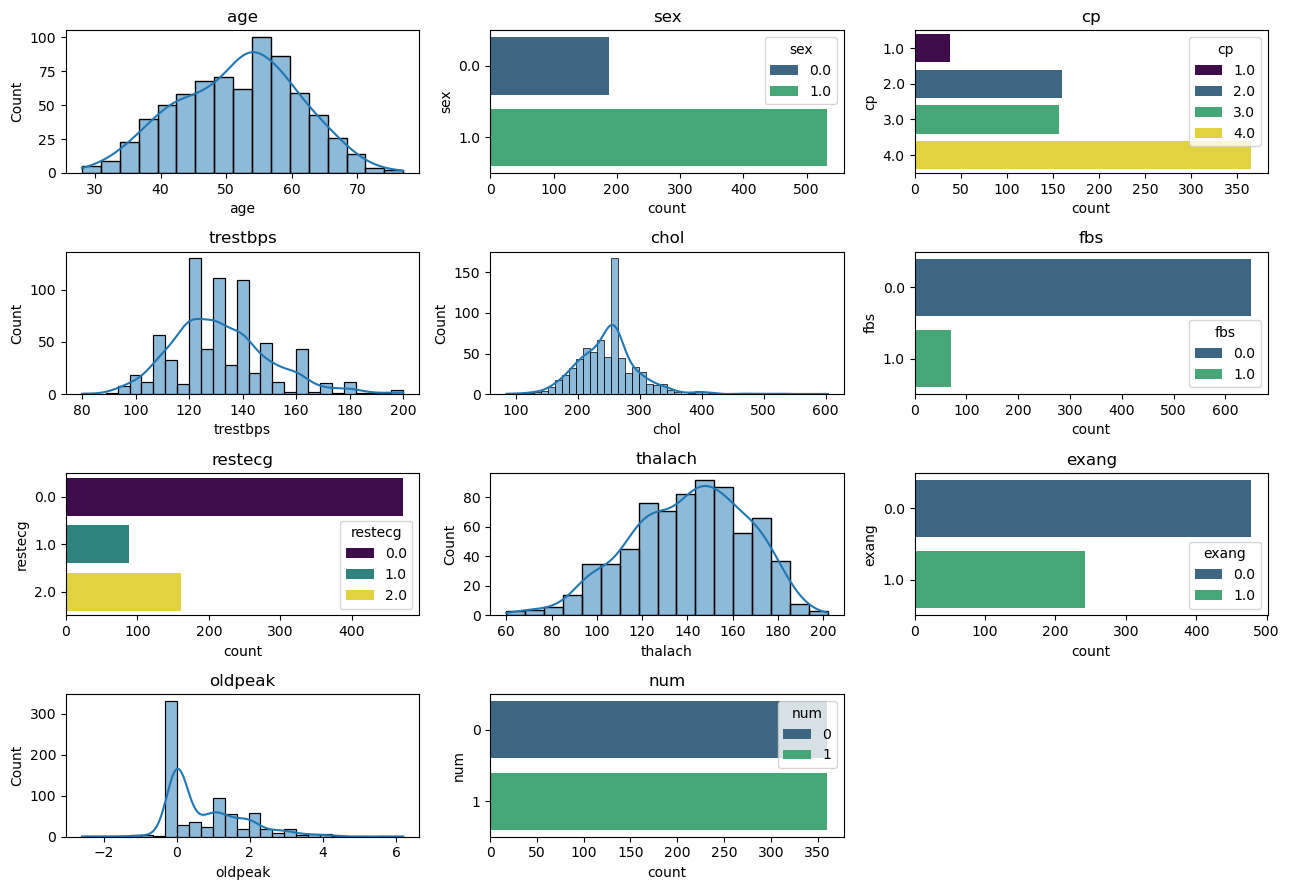

In [226]:
representacion_de_las_variables(df2)

In [228]:
df2.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'num'],
      dtype='object')

##### Pregunta 1 - c.

##### Construye una matriz de correlaciones con un heatmap, para las variables continuas.

In [230]:
# lista con las variables continuas en df2:

var_cont = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

In [232]:
# Colocamos las variables continuas en otro dataframe
df2_var_cont = df2[['age', 'trestbps', 'chol', 'thalach', 'oldpeak']]

In [234]:
df2_var_cont.head()

,age,trestbps,chol,thalach,oldpeak
0,63.0,145.0,233.0,150.0,2.3
1,67.0,160.0,286.0,108.0,1.5
2,67.0,120.0,229.0,129.0,2.6
3,37.0,130.0,250.0,187.0,3.5
4,41.0,130.0,204.0,172.0,1.4


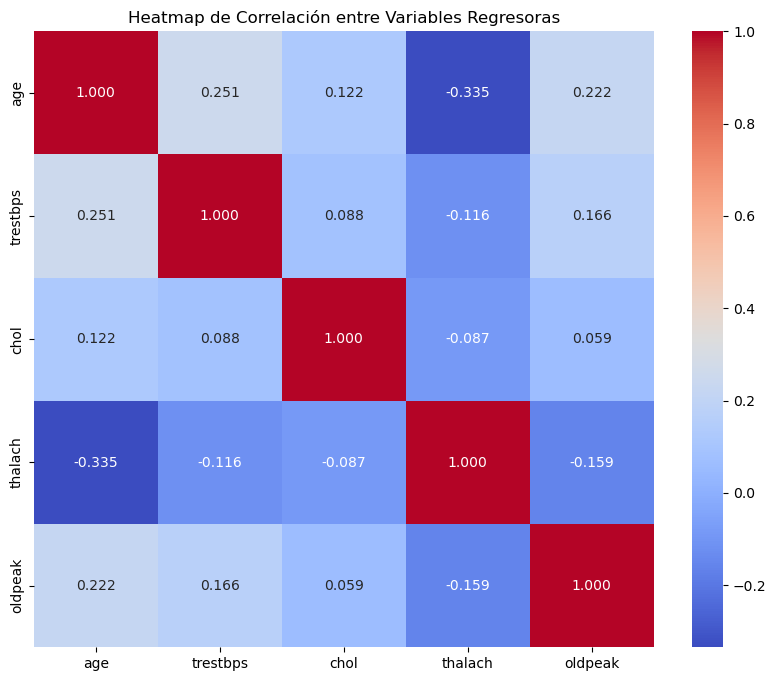

In [239]:
# Calculamos la matriz de correlación
correlation_matrix = df2_var_cont.corr()

# Creamos el heatmap de las correlaciones
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".3f", cbar=True)
plt.title("Heatmap de Correlación entre Variables Regresoras")
plt.show()

In [241]:
# Otro forma de realizarlo

# Análisis de correlaciones
corr = df2_var_cont.corr()
corr.style.background_gradient(cmap='coolwarm')

,age,trestbps,chol,thalach,oldpeak
age,1.000000,0.251155,0.122151,-0.334551,0.222433
trestbps,0.251155,1.000000,0.087681,-0.116333,0.165995
chol,0.122151,0.087681,1.000000,-0.087230,0.058618
thalach,-0.334551,-0.116333,-0.087230,1.000000,-0.158734
oldpeak,0.222433,0.165995,0.058618,-0.158734,1.000000


Podemos ver que en general que entre las variables continuas no poseen mucha correlación.

Sin embargo algunas variables a recalcar vendrían a ser las siguientes relaciones:
- thalach <-> age
- trestbps <-> age

thalach viene a ser la frecuencia cardíaca máxima alcanzada. Por lo cual, indica que la edad que uno tiene influye bastante en la frecuencia cardíaca máxima alcanzada.

trestbps viene a ser la presión arterial en reposo. Por lo cual, indica que la edad también influye en la presión arterial en reposo de un paciente.

#### Pregunta 2

2. Divide la muestra en entrenamiento y test (33%), y con ello:

   - a. Entrena un modelo de ensamble secuencial **AdaBoost**
   - b. Entrena un modelo de ensamble secuencial **Gradient Boosting**
   - c. Entrena un modelo de ensamble secuencial **XGBoosting**

Para cada uno, utiliza hiperparámetros por defecto y muestra su desempeño usando las métricas adecuadas. Comenta.

##### Vamos a utilizar df3_concat debido a que tiene las varibles dummies de las variables que tenian 3 o mas categorias

In [244]:
df3_concat.head(5)

,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,num,cp_2.0,cp_3.0,cp_4.0,restecg_1.0,restecg_2.0
0,63.0,1.0,145.0,233.0,1.0,150.0,0.0,2.3,0,0,0,0,0,1
1,67.0,1.0,160.0,286.0,0.0,108.0,1.0,1.5,1,0,0,1,0,1
2,67.0,1.0,120.0,229.0,0.0,129.0,1.0,2.6,1,0,0,1,0,1
3,37.0,1.0,130.0,250.0,0.0,187.0,0.0,3.5,0,0,1,0,0,0
4,41.0,0.0,130.0,204.0,0.0,172.0,0.0,1.4,0,1,0,0,0,1


##### Procedemos a dividir la muestra en entrenamiento y test (33%)

In [246]:
# Dividimos el DataFrame en variables predictoras (X) y objetivo (y)
X = df3_concat.drop(columns=['num'])  # Todas las columnas excepto 'num'
y = df3_concat['num']

# Dividimos el conjunto de entrenamiento y prueba (33% prueba)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

   - a. Entrena un modelo de ensamble secuencial **AdaBoost**

##### Modelo de esamble secuencial AdaBoost

In [248]:
# Procedemos a entrenar el modelo AdaBoostClassifier con hiperparámetros por defecto
adabc_model = AdaBoostClassifier(random_state=42)
adabc_model.fit(X_train, y_train)

# Realizamos las predicciones en el conjunto de test
y_pred_adabc = adabc_model.predict(X_test)

C:\Users\josek\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


Mostramos las métricas de desempeño en el conjunto de test

In [250]:
# Mostramos las métricas de evaluación
print("Desempeño del modelo AdaBoost en el conjunto de test:\n")

print(f"Accuracy: {accuracy_score(y_test, y_pred_adabc):.4f}")
print(f"F1 Score: {f1_score(y_test, y_pred_adabc):.4f}\n")

print("Matriz de confusión:")
print(confusion_matrix(y_test, y_pred_adabc))

Desempeño del modelo AdaBoost en el conjunto de test:

Accuracy: 0.8067
F1 Score: 0.8067

Matriz de confusión:
[[96 26]
 [20 96]]


In [252]:
print("\nReporte de clasificación:\n")
print(classification_report(y_test, y_pred_adabc))


Reporte de clasificación:

              precision    recall  f1-score   support

           0       0.83      0.79      0.81       122
           1       0.79      0.83      0.81       116

    accuracy                           0.81       238
   macro avg       0.81      0.81      0.81       238
weighted avg       0.81      0.81      0.81       238



   - b. Entrena un modelo de ensamble secuencial **Gradient Boosting**

##### Modelo de esamble secuencial Gradient Boosting

In [254]:
# Procedemos a entrenar el modelo GradientBoostingClassifier con hiperparámetros por defecto
gbc_model = GradientBoostingClassifier(random_state=42)
gbc_model.fit(X_train, y_train)

# Realizamos las predicciones en el conjunto de test
y_pred_gbc = gbc_model.predict(X_test)

Mostramos las métricas de desempeño en el conjunto de test

In [256]:
# Mostramos las métricas de evaluación
print("Desempeño del modelo Gradient Boosting en el conjunto de test:\n")

print(f"Accuracy: {accuracy_score(y_test, y_pred_gbc):.4f}")
print(f"F1 Score: {f1_score(y_test, y_pred_gbc):.4f}\n")

print("Matriz de confusión:")
print(confusion_matrix(y_test, y_pred_gbc))

Desempeño del modelo Gradient Boosting en el conjunto de test:

Accuracy: 0.8319
F1 Score: 0.8305

Matriz de confusión:
[[100  22]
 [ 18  98]]


In [258]:
print("\nReporte de clasificación:\n")
print(classification_report(y_test, y_pred_gbc))


Reporte de clasificación:

              precision    recall  f1-score   support

           0       0.85      0.82      0.83       122
           1       0.82      0.84      0.83       116

    accuracy                           0.83       238
   macro avg       0.83      0.83      0.83       238
weighted avg       0.83      0.83      0.83       238



   - c. Entrena un modelo de ensamble secuencial **XGBoosting**

##### Modelo de esamble secuencial XGBoosting

In [260]:
# Procedemos a entrenar el modelo XGBClassifier con hiperparámetros por defecto
xgb_model = XGBClassifier(random_state=42)
xgb_model.fit(X_train, y_train)

# Realizamos las predicciones en el conjunto de test
y_pred_xgb = xgb_model.predict(X_test)

##### Mostramos las métricas de desempeño en el conjunto de test

In [262]:
# Mostramos las métricas de evaluación
print("Desempeño del modelo XGBoosting en el conjunto de test:\n")

print(f"Accuracy: {accuracy_score(y_test, y_pred_xgb):.4f}")
print(f"F1 Score: {f1_score(y_test, y_pred_xgb):.4f}\n")

print("Matriz de confusión:")
print(confusion_matrix(y_test, y_pred_xgb))

Desempeño del modelo XGBoosting en el conjunto de test:

Accuracy: 0.8277
F1 Score: 0.8270

Matriz de confusión:
[[99 23]
 [18 98]]


In [264]:
print("\nReporte de clasificación:\n")
print(classification_report(y_test, y_pred_xgb))


Reporte de clasificación:

              precision    recall  f1-score   support

           0       0.85      0.81      0.83       122
           1       0.81      0.84      0.83       116

    accuracy                           0.83       238
   macro avg       0.83      0.83      0.83       238
weighted avg       0.83      0.83      0.83       238



Despues de haber evualuado los modelos con las métricas de desempeño, podemos concluir que el mejor modelo es **Gradient Boosting** al tener el F1 Score más alto con un **F1 Score = 0.8305**

#### Pregunta 3

3. Realiza una búsqueda del hiper parámetro para el modelo que resulte tener mejor desempeño (utiliza **f1-score** para determinarlo). Los valores a buscar para la grilla son:

   - a. `n_estimators`: 20 a 200 con 15 valores
   - b. `learning_rate`: 0.004 a 1.0 con 40 valores
   - c. `sub_sample`: 0.1 a 1.0 con 18 valores

Muestra los mejores hiper parámetros encontrados y entrena un modelo con estos, presentando sus métricas.

In [266]:
# Seleccionamos el modelo Gradient Boosting para la búsqueda de hiperparámetros
model = GradientBoostingClassifier(random_state=42)

# Definimos los parámetros de la grilla
param_grid = {
    'n_estimators': np.linspace(20, 200, 15, dtype=int),
    'learning_rate': np.linspace(0.004, 1.0, 40),
    'subsample': np.linspace(0.1, 1.0, 18)
}

# Configuramos el GridSearchCV con una validación cruzada de 5 pliegues
# n_jobs=-1 -> usamos todos los nucleos disponibles
grid_search = GridSearchCV(estimator=model, param_grid=param_grid, cv=5, scoring='f1', n_jobs=-1, verbose=1)

# Entrenamos el modelo
grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 10800 candidates, totalling 54000 fits


GridSearchCV(cv=5, estimator=GradientBoostingClassifier(random_state=42),
             n_jobs=-1,
             param_grid={'learning_rate': array([0.004     , 0.02953846, 0.05507692, 0.08061538, 0.10615385,
       0.13169231, 0.15723077, 0.18276923, 0.20830769, 0.23384615,
       0.25938462, 0.28492308, 0.31046154, 0.336     , 0.36153846,
       0.38707692, 0.41261538, 0.43815385, 0.46369231, 0.48923077,
       0.51476923, 0.54030769, 0...
       0.89784615, 0.92338462, 0.94892308, 0.97446154, 1.        ]),
                         'n_estimators': array([ 20,  32,  45,  58,  71,  84,  97, 110, 122, 135, 148, 161, 174,
       187, 200]),
                         'subsample': array([0.1       , 0.15294118, 0.20588235, 0.25882353, 0.31176471,
       0.36470588, 0.41764706, 0.47058824, 0.52352941, 0.57647059,
       0.62941176, 0.68235294, 0.73529412, 0.78823529, 0.84117647,
       0.89411765, 0.94705882, 1.        ])},
             scoring='f1', verbose=1)

##### Mostramos los mejores hiper parámetros encontrados

In [274]:
print("Mejores valores de hiper parámetros encontrados:")
print(grid_search.best_params_)

Mejores valores de hiper parámetros encontrados:
{'learning_rate': 0.08061538461538462, 'n_estimators': 122, 'subsample': 0.9470588235294117}


In [276]:
# Obtenemos el mejor modelo encontrado por GridSearchCV (entrena un modelo con los mejores hiper parámetros encontrados)
best_model = grid_search.best_estimator_

# Realizamos las predicciones con el mejor modelo en el conjunto de test
y_pred = best_model.predict(X_test)

##### Mostramos las métricas de desempeño en el conjunto de test

In [278]:
# Mostramos las métricas de evaluación
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"F1 Score: {f1_score(y_test, y_pred):.4f}\n")

print("Matriz de confusión:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8361
F1 Score: 0.8340

Matriz de confusión:
[[101  21]
 [ 18  98]]


In [280]:
print("\nReporte de clasificación:\n")
print(classification_report(y_test, y_pred))


Reporte de clasificación:

              precision    recall  f1-score   support

           0       0.85      0.83      0.84       122
           1       0.82      0.84      0.83       116

    accuracy                           0.84       238
   macro avg       0.84      0.84      0.84       238
weighted avg       0.84      0.84      0.84       238



##### Recordar que las métricas del modelo Gradient Boosting sin la búsqueda del hiper parámetro, son las siguientes:
- Accuracy: 0.8319
- F1 Score: 0.8305

##### y con la búsqueda del hiper parámetro son las siguientes:
- Accuracy: 0.8361
- F1 Score: 0.8340

Por lo cual, podemos ver que las métricas del modelo se han mejorado, pero muy poco. Asimismo, si comparamos las matrices de confusión y los reportes de clasificación casi no varían. 

Por lo tanto, podemos mencionar que no será necesario implementar un modelo Gradient Boosting con búsqueda del hiper parámetro debido a que no mejoro considerablmente respecto al modelo Gradient Boosting y, además, consume más computacionalmente.

#### Pregunta 4

4. Elabora un gráfico con las curvas ROC para cada modelo entrenado, y a partir de ello recomienda alguno de ellos. Justifica la decisión.

Para realizar las curvas ROC de cada modelo, necesitamos calcular las probabilidades de cada una de las observaciones de cada uno de los modelos.

##### Por lo cual, como primer paso predecimos las probabilidades para el conjunto de test (para la clase 1) de cada uno de los modelos

In [282]:
# probabilidades para el modelo AdaBoost
yhat_roc_adabc = adabc_model.predict_proba(X_test)[:, 1]

# Uitilizamos el modelo Gradient Boosting con búsqueda del hiper parámetro en vez del Gradient Boosting
# probabilidades para el modelo Gradient Boosting con búsqueda del hiper parámetro
yhat_roc_best = best_model.predict_proba(X_test)[:, 1]

# probabilidades para el modelo XGBoosting
yhat_roc_xgb = xgb_model.predict_proba(X_test)[:, 1]

##### Calculamos la curva ROC para los modelos

In [284]:
# fpr -> false positive rate
# tpr -> true positive rate
# threshold -> umbral de decisión

fpr_adabc, tpr_adabc, threshold_adabc = roc_curve(y_test, yhat_roc_adabc)

fpr_best, tpr_best, threshold_best = roc_curve(y_test, yhat_roc_best)

fpr_xgb, tpr_xgb, threshold_xgb = roc_curve(y_test, yhat_roc_xgb)

##### Calculamos el AUC para los modelos

In [286]:
auc_adabc = roc_auc_score(y_test, yhat_roc_adabc)
print(f"AUC para el modelo AdaBoost: {auc_adabc:.3f}")

auc_best = roc_auc_score(y_test, yhat_roc_best)
print(f"AUC para el modelo Gradient Boosting con búsqueda del hiper parámetro: {auc_best:.3f}")

auc_xgb = roc_auc_score(y_test, yhat_roc_xgb)
print(f"AUC para el modelo XGBoosting: {auc_xgb:.3f}")

AUC para el modelo AdaBoost: 0.878
AUC para el modelo Gradient Boosting con búsqueda del hiper parámetro: 0.912
AUC para el modelo XGBoosting: 0.898


##### Procedemos a graficar la curva ROC para los modelos

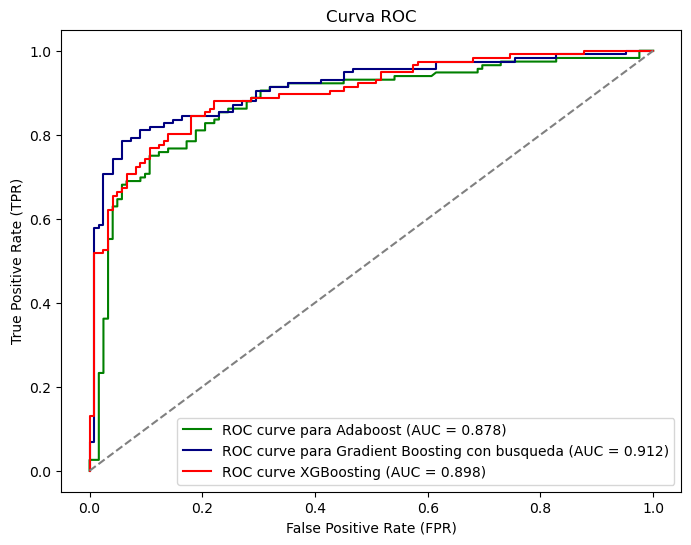

In [288]:
plt.figure(figsize=(8, 6))

# Graficamos las curvas ROC de los modelos

# AdaBoost
plt.plot(fpr_adabc, tpr_adabc, color='green', label=f'ROC curve para Adaboost (AUC = {auc_adabc:.3f})')

# Gradient Boosting con búsqueda del hiper parámetro
plt.plot(fpr_best, tpr_best, color='navy', label=f'ROC curve para Gradient Boosting con busqueda (AUC = {auc_best:.3f})')

# XGBoosting
plt.plot(fpr_xgb, tpr_xgb, color='red', label=f'ROC curve XGBoosting (AUC = {auc_xgb:.3f})')

plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  # Línea de referencia
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Curva ROC')
plt.legend(loc="lower right")
plt.show()

Podemos ver que el modelo que tiene el más alto AUC viene a ser el modelo Gradient Boosting con búsqueda del hiper parámetro. El cual posee más de 0.9 de AUC, lo cual indica un muy buen desempeño. 

Asimismo, podemos ver que el AUC del modelo XGBoosting está muy próximo al 0.9 y el AUC del modelo Adaboost también se encuentra próximo a 0.9. Lo cual indican que también tienen buen desempeño.

##### Entonces, podemos concluir que a pesar de que el modelo Gradient Boosting con búsqueda del hiper parámetro tenga un AUC de 0.9 este no distancia mucho de los demás modelos. Y por facilidad y ahorro, podría ser lo mejor escoger el modelo XGBoosting al tener un AUC muy próximo a 0.9 y tener unas buenas métricas su modelo.

#### Pregunta 5

5. Muestra las variables por nivel de importancia para el mejor modelo, luego de la búsqueda de hiper parámetro. Comenta.

In [290]:
# datos con la importancia de cada variable
importances = best_model.feature_importances_

# nombre de las variables
feature_names = X_train.columns

In [292]:
# Generamos un DataFrame con las columnas del X_train y con sus respectivas importancias
importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})

# Ordenamos el DataFrame
importance_df = importance_df.sort_values(by='Importance', ascending=False)

In [294]:
importance_df

,Feature,Importance
10,cp_4.0,0.301113
3,chol,0.237777
7,oldpeak,0.107361
6,exang,0.098485
5,thalach,0.073463
1,sex,0.060446
0,age,0.052340
2,trestbps,0.046139
11,restecg_1.0,0.009174
4,fbs,0.005423


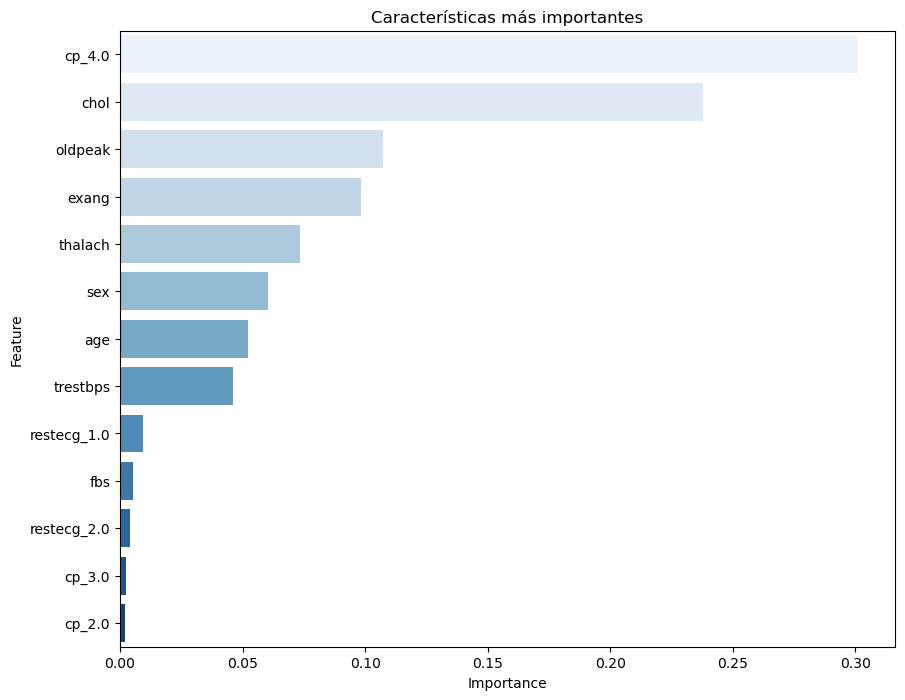

In [302]:
plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Feature', data=importance_df, hue='Feature', palette='Blues', dodge=False)
plt.title('Características más importantes')
plt.show()

Podemos ver que las variables más importantes a evaluar para ver si un paciente tiene cardiopatía son las siguientes:
- cp_4.0: Si tiene un dolor torácico asintomático
- chol: Colesterol sérico en mg/dl
- oldpeak: Depresión del ST inducida por el ejercicio en relación con el reposo
- exang: Angina inducida por ejercicio (1 = sí; 0 = no)

Debido a que influyen en la variable 'num' con aproximadamente 10% o más.